# 01 — Dados: carga, qualidade e exposição

**Objetivo.** Transformar a base bruta (estipulantes, vidas, sinistros, prêmios) em uma tabela de experiência
auditável: exposição em vidas-ano e capital-ano, óbitos e valores esperados pela tábua, e observados.

**O que este notebook NÃO faz:** precificar. Ele entrega a base que as etapas seguintes (taxa manual,
credibilidade, camada bayesiana) consomem.

**Convenções** (detalhes em `config/base.yaml` e em `src/vgpricing/exposicao.py`):
- segmento cobre de `data_inicio` a `data_fim`, inclusive; `data_fim` vazia = em vigor;
- ano-apólice vai do aniversário até a véspera do seguinte; o último pode ser parcial;
- idade = idade completa no início de cada pedaço de exposição;
- esperado = q_x × exposição (aproximação linear);
- observados = sinistros **avisados** até a data de referência (o IBNR entra na etapa de renovação);
- tábua base: BR-EMSmt 2026 oficial (SUSEP), conferida a cada carga.

Toda a lógica está no pacote `vgpricing`, coberto por testes (`pytest`). O notebook só orquestra.

In [14]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing.io import ler_pasta, ler_excel, salvar_pasta
from vgpricing.sintetico import gerar_carteira, injetar_sujeira, tabelas_de_entrada
from vgpricing.validacao import validar
from vgpricing.exposicao import exposicao_detalhada, experiencia

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg = carregar_config("base", RAIZ)
mapas = carregar_config("colunas", RAIZ)
DATA_REF = cfg["data_referencia"]

# Tábua oficial BR-EMSmt 2026: baixada da SUSEP na primeira execução e travada pelo hash do config.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")   # achado documentado abaixo
    tabua = obter_tabua(cfg, RAIZ)
if tabua.placeholder:
    raise RuntimeError("Tábua oficial não carregada. Rode vgpricing.tabua.baixar_tabua_susep() "
                       "ou veja data/external/README.md.")
print(f"Tábua: {tabua.nome}\nsha256: {tabua.sha256}")
print("Abas lidas:", tabua.meta["abas"])
print("Mortalidade mt/sb entre 20 e 80 anos (deve ser > 1):", tabua.meta["checagem_mt_maior_que_sb"])
print("Conferência do q_x contra o e_x publicado (deve ser consistente):")
display(pd.DataFrame(tabua.meta["conciliacao_ex"]).T)
print("Conferência do q_x contra o l_x (no arquivo 2026 o l_x está defasado em 1 idade; só informativo):")
display(pd.DataFrame(tabua.meta["conciliacao_lx"]).T[["max_dif_rel", "max_dif_rel_lx_defasado_1_idade", "diagnostico"]])
display((tabua.qx.loc[[20, 30, 40, 50, 60, 70]] * 1000).rename(columns=lambda s: f"q_x por mil ({s})"))

Tábua: BR-EMSmt-2026
sha256: 45a1565083c77042187c1364a58d0f27d90208f140124394d179fb2b8cd70541
Abas lidas: {'M': 'BR-EMSmt-2026-m', 'F': 'BR-EMSmt-2026-f'}
Mortalidade mt/sb entre 20 e 80 anos (deve ser > 1): {'M': 1.293716568596024, 'F': 1.5130687896581514}
Conferência do q_x contra o e_x publicado (deve ser consistente):


,disponivel,max_dif_anos,idade_max_dif,consistente
M,True,0.0499,71,True
F,True,0.0494,59,True


Conferência do q_x contra o l_x (no arquivo 2026 o l_x está defasado em 1 idade; só informativo):


,max_dif_rel,max_dif_rel_lx_defasado_1_idade,diagnostico
M,0.0873,0.0007,lx defasado em 1 idade
F,0.0927,0.0019,lx defasado em 1 idade


,q_x por mil (M),q_x por mil (F)
idade,,
20,1.0324,0.3513
30,1.1480,0.5150
40,1.5071,0.8954
50,3.3459,2.0481
60,8.2498,5.2297
70,20.5481,13.7277


**Achados na tábua oficial (BR-EMS 2026, arquivo da SUSEP, SHA-256 no config):**
- A coluna `lx` das abas 2026 está defasada em uma idade em relação à `qx`: ela bate com
  q_(x+1), não com q_x. A coluna `ex` publicada bate com a `qx` (diferença ≤ 0,05 ano, dentro do
  arredondamento), então a `qx` é a que gerou a tábua. O cálculo usa só a `qx`. Nas versões 2015 e
  2021, as três colunas são consistentes.
- A tábua masculina tem q_x decrescente entre 26 e 31 anos ("corcova de acidentes"). É padrão
  demográfico, não erro; a validação de monotonicidade começa aos 35 anos.
- O título da aba BR-EMSmt-2026-m menciona "Sobrevivência"; a identidade da tábua é conferida
  numericamente (mortalidade mt maior que sb na mesma versão).

## 1. Fonte dos dados

`FONTE = "sintetico"` gera a carteira de teste. Para dados reais, troque para `"excel"` (template em
`templates/`) ou `"pasta"` (parquet/CSV extraídos do banco) e ajuste só `config/colunas.yaml`.

In [15]:
FONTE = "sintetico"   # "sintetico" | "excel" | "pasta"

if FONTE == "sintetico":
    cfg_s = carregar_config("sintetico", RAIZ)
    carteira = gerar_carteira(cfg_s, tabua)
    suja, verdade_sujeira = injetar_sujeira(carteira, cfg_s)
    salvar_pasta(tabelas_de_entrada(suja), RAIZ / "data/synthetic")
    # relê pelo mesmo caminho que um dado real usaria
    dados, problemas_leitura = ler_pasta(RAIZ / "data/synthetic", mapas, "parquet")
elif FONTE == "excel":
    dados, problemas_leitura = ler_excel(RAIZ / "data/raw/entrada.xlsx", mapas)
else:
    dados, problemas_leitura = ler_pasta(RAIZ / "data/raw", mapas, "parquet")

pd.DataFrame({k: [len(v)] for k, v in dados.items()}, index=["linhas"])

,estipulantes,vidas,sinistros,premios
linhas,250,875294,2273,1280


In [16]:
print("Problemas de conversão de tipo na leitura:", len(problemas_leitura))
problemas_leitura.head()

Problemas de conversão de tipo na leitura: 0


,tabela,coluna,id_linha,valor_original,tipo_esperado


## 2. Qualidade de dados

Cada regra tem código, severidade e ação (`excluir` ou `sinalizar`). Regras rodam em ordem; um registro
excluído não é reavaliado pelas regras seguintes. Nada é corrigido automaticamente: o log abaixo é o que
vai para o time de cadastro e para a auditoria.

In [17]:
res = validar(dados, cfg)
res.resumo()

c:\Users\Arthur\Documents\VS Code\Projetos\vida-grupo-pricing\src\vgpricing\validacao.py:59: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(self.linhas, ignore_index=True)


,codigo,tabela,descricao,acao,severidade,registros
0,P01,premios,prêmio emitido difere de taxa × capital-ano em...,sinalizar,media,43
1,S01,sinistros,sinistro duplicado,excluir,alta,45
2,S02,sinistros,vida não encontrada na base de vidas (mantido ...,sinalizar,alta,22
3,S03,sinistros,ocorrência fora de período de cobertura na bas...,sinalizar,alta,17
4,S04,sinistros,aviso anterior à ocorrência,sinalizar,media,22
5,S06,sinistros,sinistro negado: fora da experiência,excluir,info,71
6,V01,vidas,linha duplicada,excluir,media,4355
7,V03,vidas,nascimento ausente ou posterior ao início,excluir,alta,871
8,V04,vidas,idade de entrada impossível,excluir,alta,1742
9,V05,vidas,sexo ausente/inválido (usa média M/F da tábua),sinalizar,media,4355


**Prova de detecção (só no sintético).** O gerador registrou exatamente quais linhas sujou e qual regra
deveria pegá-las. A tabela compara.

In [18]:
if FONTE == "sintetico":
    ex = res.excecoes
    linhas = []
    for (tab, cod), g in verdade_sujeira.groupby(["tabela", "codigo"]):
        col = "id_linha" if tab == "vidas" else "id_sinistro"
        marc = set(ex.loc[ex["codigo"] == cod, col].astype(str)); inj = set(g["chave"].astype(str))
        linhas.append({"regra": cod, "injetados": len(inj), "detectados": len(marc & inj),
                       "nao_detectados": len(inj - marc), "falsos_alarmes": len(marc - inj)})
    display(pd.DataFrame(linhas))

,regra,injetados,detectados,nao_detectados,falsos_alarmes
0,S01,45,45,0,0
1,S02,22,22,0,0
2,S04,22,22,0,0
3,V01,4355,4355,0,0
4,V03,871,871,0,0
5,V04,1742,1742,0,0
6,V05,4355,4355,0,0
7,V06,871,871,0,0
8,V07,871,871,0,0


Sinistros sinalizados com `S03` (ocorrência fora de cobertura) que não foram injetados são consequência
esperada: a vida tinha o segmento do óbito sujo e ele foi excluído. Na base real, isso indica que o sinistro
precisa de investigação de cadastro antes de entrar no cálculo de renovação.

In [19]:
ex = res.excecoes
ex[ex["codigo"] == "S03"].head()

,codigo,tabela,descricao,severidade,acao,id_linha,id_sinistro,id_estipulante,detalhe
15923,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,287,SIN0000296,EST0029,
15924,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,342,SIN0000357,EST0035,
15925,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,514,SIN0000536,EST0049,
15926,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,529,SIN0000552,EST0051,
15927,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,732,SIN0000764,EST0076,


## 3. Exposição e experiência

A tabela de experiência é estipulante × ano-apólice. `n_efetivo` é o número efetivo de óbitos esperados
quando o A/E é ponderado por capital: (Σ C·q·t)² / Σ C²·q·t. Ele cai quando o capital é concentrado em
poucas vidas, e é ele (não o número de vidas) que deve dar o peso de credibilidade na renovação.

In [20]:
det = exposicao_detalhada(res.dados["vidas"], res.dados["estipulantes"], tabua, DATA_REF,
                          cfg["exposicao"]["dias_por_ano"])
xp = experiencia(det, res.dados["sinistros"], res.dados["estipulantes"], DATA_REF)
xp.head()

,id_estipulante,ano_apolice,vidas_ano,capital_ano,obitos_esperados,valor_esperado,soma_c2q,obitos_observados,valor_observado,n_efetivo,ae_obitos,ae_valor
0,EST0000,1,147.5756,"16,145,650.3765",0.2160,"23,058.4427","3,901,965,099.0306",1.0000,"55,200.0000",0.1363,4.6298,2.3939
1,EST0000,2,146.9870,"17,082,067.0773",0.2331,"27,798.2486","5,010,492,258.5370",0.0000,0.0000,0.1542,0.0000,0.0000
2,EST0000,3,155.5619,"18,441,163.8604",0.2365,"28,654.9378","5,258,707,154.8965",1.0000,"97,900.0000",0.1561,4.2292,3.4165
3,EST0000,4,178.2094,"20,886,018.8912",0.2709,"32,110.8827","5,842,680,924.9669",0.0000,0.0000,0.1765,0.0000,0.0000
4,EST0000,5,110.0014,"13,156,653.2512",0.1716,"19,360.0304","3,482,021,577.1861",1.0000,"92,800.0000",0.1076,5.8259,4.7934


In [21]:
tot = xp[["vidas_ano", "capital_ano", "obitos_esperados", "obitos_observados",
           "valor_esperado", "valor_observado"]].sum()
resumo = pd.Series({
    "estipulantes": xp["id_estipulante"].nunique(),
    "vidas-ano": tot["vidas_ano"],
    "capital-ano (R$ bi)": tot["capital_ano"] / 1e9,
    "óbitos esperados": tot["obitos_esperados"],
    "óbitos observados (avisados)": tot["obitos_observados"],
    "A/E óbitos": tot["obitos_observados"] / tot["obitos_esperados"],
    "A/E valor": tot["valor_observado"] / tot["valor_esperado"],
})
resumo.to_frame("carteira")

,carteira
estipulantes,250.0000
vidas-ano,"1,148,347.6824"
capital-ano (R$ bi),88.0127
óbitos esperados,"2,158.0574"
óbitos observados (avisados),"2,157.0000"
A/E óbitos,0.9995
A/E valor,0.9404


### A/E por seção CNAE, com intervalo exato de Poisson (95%)

Intervalo de Garwood para o número de óbitos, dividido pelos esperados. Serve de primeira leitura antes do
modelo da Etapa 2, que separa a atividade do capital, das demais características e do efeito de cada grupo.

In [22]:
det_s = det.merge(res.dados["estipulantes"][["id_estipulante", "cnae_secao"]], on="id_estipulante")
xs = experiencia(det_s, res.dados["sinistros"], res.dados["estipulantes"], DATA_REF, por=("cnae_secao",))
O, E = xs["obitos_observados"], xs["obitos_esperados"]
xs["ae_inf"] = np.where(O > 0, chi2.ppf(0.025, 2 * O) / 2, 0) / E
xs["ae_sup"] = chi2.ppf(0.975, 2 * (O + 1)) / 2 / E
xs = xs.sort_values("ae_obitos")
if FONTE == "sintetico":
    xs = xs.merge(pd.DataFrame([{"cnae_secao": s, "nome": v["nome"], "fator_hipotese": v["fator_mortalidade"]}
                                for s, v in cfg_s["secoes"].items()]), on="cnae_secao")
xs[[c for c in ["cnae_secao", "nome", "vidas_ano", "obitos_esperados", "obitos_observados", "ae_obitos",
                "ae_inf", "ae_sup", "fator_hipotese"] if c in xs]]

,cnae_secao,nome,vidas_ano,obitos_esperados,obitos_observados,ae_obitos,ae_inf,ae_sup,fator_hipotese
0,O,Administração pública,"149,392.8515",419.7398,313,0.7457,0.6654,0.8331,0.9500
1,M,"Atividades profissionais, científicas e técnicas","80,068.0383",116.9125,91,0.7784,0.6267,0.9557,0.9000
2,P,Educação,"86,236.5120",152.7513,120,0.7856,0.6513,0.9394,0.9000
3,K,Atividades financeiras,"121,348.5585",173.6446,153,0.8811,0.7470,1.0323,0.8500
4,Q,Saúde humana e serviços sociais,"64,063.1869",92.4069,84,0.9090,0.7251,1.1254,1.0000
5,G,Comércio,"76,533.7029",93.0847,95,1.0206,0.8257,1.2476,1.0500
6,N,Atividades administrativas e serviços compleme...,"233,888.5914",367.2237,387,1.0539,0.9515,1.1643,1.0000
7,C,Indústrias de transformação,"133,462.7324",266.3021,289,1.0852,0.9637,1.2178,1.1500
8,F,Construção,"99,140.5202",201.7091,246,1.2196,1.0719,1.3819,1.3500
9,H,"Transporte, armazenagem e correio","104,212.9884",274.2829,379,1.3818,1.2462,1.5281,1.3000


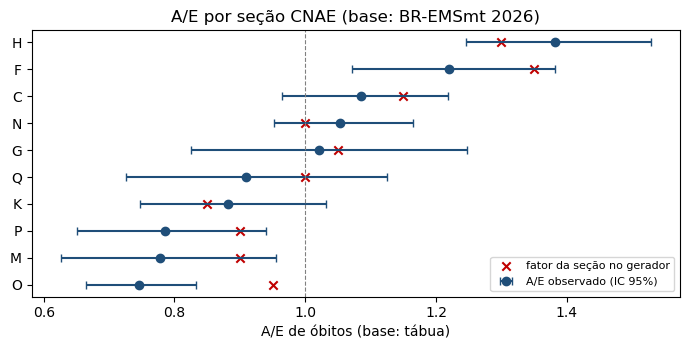

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(xs))
ax.errorbar(xs["ae_obitos"], y, xerr=[xs["ae_obitos"] - xs["ae_inf"], xs["ae_sup"] - xs["ae_obitos"]],
            fmt="o", color="#1f4e79", capsize=3, label="A/E observado (IC 95%)")
if "fator_hipotese" in xs:
    ax.scatter(xs["fator_hipotese"], y, marker="x", color="#c00000", label="fator da seção no gerador")
ax.axvline(1, color="grey", lw=0.8, ls="--")
ax.set_yticks(y, xs["cnae_secao"]); ax.set_xlabel("A/E de óbitos (base: tábua)")
ax.set_title("A/E por seção CNAE (base: BR-EMSmt 2026)")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

O A/E por seção difere do fator da seção no gerador por três motivos: os observados ainda não incluem o
IBNR (Etapa 3); os sinistros negados ficam, corretamente, fora; e cada seção carrega os efeitos das suas
divisões e dos seus estipulantes, que só se anulam em média. Separar esses efeitos é o papel do modelo da
Etapa 2.

### Por que o número efetivo importa

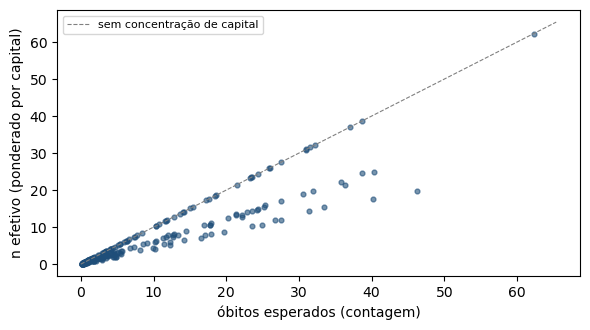

count   250.0000
mean      0.7424
std       0.2247
min       0.3605
25%       0.5915
50%       0.6477
75%       1.0000
max       1.0000
Name: razao_n_ef_por_esperados, dtype: float64

In [24]:
grp = xp.groupby("id_estipulante")[["vidas_ano", "obitos_esperados", "valor_esperado", "soma_c2q"]].sum()
grp["n_efetivo"] = grp["valor_esperado"] ** 2 / grp["soma_c2q"]
grp["razao_n_ef_por_esperados"] = grp["n_efetivo"] / grp["obitos_esperados"]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(grp["obitos_esperados"], grp["n_efetivo"], s=12, alpha=0.6, color="#1f4e79")
lim = grp["obitos_esperados"].max() * 1.05
ax.plot([0, lim], [0, lim], color="grey", ls="--", lw=0.8, label="sem concentração de capital")
ax.set_xlabel("óbitos esperados (contagem)"); ax.set_ylabel("n efetivo (ponderado por capital)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
grp["razao_n_ef_por_esperados"].describe()

Grupos com capital uniforme ficam na diagonal. Em grupos com múltiplo salarial ou capital escalonado,
o n efetivo é bem menor que a contagem de óbitos esperados: usar a contagem daria credibilidade demais a
grupos cuja sinistralidade em R$ depende de poucas vidas de capital alto.

## 4. Conciliação de prêmio

In [25]:
p = res.dados.get("premios")
if p is not None and "dif_rel" in p:
    print("Períodos com divergência acima da tolerância:", int((p["dif_rel"].abs() > cfg["validacao"]["tolerancia_conciliacao_premio"]).sum()),
          "de", len(p))
    display(p["dif_rel"].describe())

Períodos com divergência acima da tolerância: 43 de 1280


count   1,280.0000
mean        0.0046
std         0.0060
min        -0.0000
25%         0.0000
50%         0.0037
75%         0.0059
max         0.0976
Name: dif_rel, dtype: float64

As divergências vêm dos registros excluídos na validação (o prêmio foi faturado sobre a base suja).
Afastados não geram divergência porque continuam faturados e entram na conciliação.

## 5. Saídas desta etapa

Gravadas em `data/synthetic/` (ou `data/processed/` no uso real): base limpa, log de exceções e tabela de
experiência. São a entrada da Etapa 2.

In [26]:
saida = RAIZ / "data" / ("synthetic" if FONTE == "sintetico" else "processed")
saida.mkdir(parents=True, exist_ok=True)
res.excecoes.to_csv(saida / "log_excecoes.csv", index=False)
xp.to_parquet(saida / "experiencia_estipulante_ano.parquet", index=False)
det.to_parquet(saida / "exposicao_detalhada.parquet", index=False)
salvar_pasta(res.dados, saida / "limpo")
if FONTE == "sintetico":
    carteira["verdade_estipulantes"].to_parquet(saida / "verdade_estipulantes.parquet", index=False)
    carteira["verdade_ibnr"].to_parquet(saida / "verdade_ibnr.parquet", index=False)
    carteira["verdade_vidas"].to_parquet(saida / "verdade_vidas.parquet", index=False)
sorted(x.name for x in saida.rglob("*") if x.is_file())

['.gitkeep',
 'estipulantes.parquet',
 'estipulantes.parquet',
 'experiencia_estipulante_ano.parquet',
 'exposicao_detalhada.parquet',
 'log_excecoes.csv',
 'premios.parquet',
 'premios.parquet',
 'sinistros.parquet',
 'sinistros.parquet',
 'verdade_estipulantes.parquet',
 'verdade_ibnr.parquet',
 'verdade_vidas.parquet',
 'vidas.parquet',
 'vidas.parquet']

## Limitações desta etapa
- A carteira é sintética: os níveis de A/E refletem as hipóteses do gerador (`config/sintetico.yaml`),
  não a experiência de mercado. A tábua base, essa sim, é a oficial.
- Esperado linear (q·t) superestima levemente em pedaços longos e idades altas; o efeito é desprezível
  para q_x de idades ativas.
- Sexo ausente usa a média M/F da tábua, sinalizado no log (V05).
- Observados ainda sem IBNR; o A/E de anos recentes está subestimado até o ajuste da Etapa 3.